# Transcript Analysis Helper

Interactively explore the transcript `.txt` files housed under `data/` using the helpers defined in `script.py`.


In [240]:
from pathlib import Path

import pandas as pd

from dataloader import TranscriptLoader

loader = TranscriptLoader()
print(f"Data directory: {loader.data_dir}")


Data directory: /Users/bentindal/Desktop/CognoSpeak/data


In [241]:
# Random seed for reproducibility
RANDOM_SEED = 42


In [242]:
from file_validator import validate_file_naming, print_validation_report

# Check for files that don't follow naming convention
naming_issues = validate_file_naming(Path(loader.data_dir))
print_validation_report(naming_issues)


FILE NAMING CONVENTION CHECK

Accepted formats:
  - Process-XXX__PFT.txt or Process-XXX__SFT.txt (double underscore)
  - Process-XXX_PFT.txt or Process-XXX_SFT.txt (single underscore)
Files should be in directories: Process-rec-XXX/ or Process-test-XXX/

✅ All files follow the naming convention!


In [243]:
transcript_paths = loader.discover_transcript_files()
len(transcript_paths), transcript_paths[:5]


(180,
 [PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-004/Process-rec-004__PFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-004/Process-rec-004__SFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-006/Process-rec-006_PFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-006/Process-rec-006_SFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-009/Process-rec-009__PFT.txt')])

In [244]:
example_path = transcript_paths[0]
example_df = loader.load_transcript(example_path)
example_df.head()


,start_time,end_time,token,recording,task,recording_number,source_path
0,0.445333,0.445333,plank,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
1,2.099429,2.099429,pool,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
2,4.835048,4.835048,pool,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
3,8.270476,8.270476,plethora,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
4,9.924571,9.924571,puzzle,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...


In [245]:
frames = loader.load_all_transcripts(transcript_paths)
combined = loader.concatenate_transcripts(frames.values())
summary = loader.summarize_structure(combined)
summary.to_frame(name='value')


,value
rows,3301
recordings,90
tasks,"PFT, SFT"
start_time_range,"(0.0, 62.605016)"
end_time_range,"(0.0, 62.690496)"
missing_values,0


In [246]:
metadata = loader.load_metadata()
metadata.head()


,recording,age,gender,diagnosis,MMSE,annotator,notes,recording_number
0,Process-rec-143,70.0,male,DEMENTIA,24.0,Madhu,"SFT: all good, something said at the end, can'...",143
1,Process-rec-091,73.0,female,DEMENTIA,20.0,Kevin,"SFT: good, repeated a couple words towards the...",91
2,Process-test-038,73.0,male,DEMENTIA,<NA>,Kevin,"SFT: good until end, noticeable pauses; PFT: n...",38
3,Process-rec-107,75.0,female,DEMENTIA,<NA>,Kevin,"SFT: good, noticeable pauses, repeated word; P...",107
4,Process-rec-040,77.0,male,DEMENTIA,<NA>,Kevin,"SFT: all good; PFT: poor, apologised for strug...",40


In [247]:
merged = loader.merge_with_metadata(combined, metadata)
merged[['recording', 'diagnosis']].drop_duplicates().head()


,recording,diagnosis
0,Process-rec-004,MCI
41,Process-rec-006,DEMENTIA
69,Process-rec-009,HC
116,Process-rec-010,HC
159,Process-rec-013,MCI


In [248]:
# Optional: persist the combined dataset for downstream work
output_path = Path('combined_transcripts.parquet')
combined.to_parquet(output_path, index=False)
output_path


PosixPath('combined_transcripts.parquet')

In [249]:
from pathlib import Path
from pause_analyzer import analyze_pauses

# Generate pause_summary.csv if it doesn't exist
pause_summary_path = Path('pause_summary.csv')
if not pause_summary_path.exists():
    print("Generating pause_summary.csv...")
    analyze_pauses(Path(loader.data_dir), pause_summary_path)
    print(f"✓ Created {pause_summary_path}")
else:
    print(f"✓ {pause_summary_path} already exists")


✓ pause_summary.csv already exists


## Pause Metrics by Diagnosis

Merge the pause statistics from `pause_summary.csv` with the subject metadata to compare cohorts (Dementia, MCI, HC).


In [250]:
import matplotlib.pyplot as plt
import seaborn as sns

pause_summary = pd.read_csv('pause_summary.csv')
pause_summary['recording'] = pause_summary['transcript'].str.split('/').str[0]

pause_with_diag = pause_summary.merge(
    metadata.rename(columns={'anyon_IDs': 'recording'})[['recording', 'diagnosis']],
    on='recording',
    how='left'
)
pause_with_diag.dropna(subset=['diagnosis'], inplace=True)
pause_with_diag.head()


,transcript,token_count,pause_count,pause_mean,pause_median,pause_min,pause_max,pause_std,pause_total,pause_q1,pause_q2,pause_q3,recording,diagnosis
0,Process-rec-004/Process-rec-004__PFT.txt,23,22,2.478251,1.972190,1.208762,7.697905,1.607948,54.521524,1.383714,1.972190,2.815143,Process-rec-004,MCI
1,Process-rec-004/Process-rec-004__SFT.txt,18,17,3.125438,2.160889,0.762667,13.028889,3.040823,53.132445,1.398222,2.160889,3.686222,Process-rec-004,MCI
2,Process-rec-006/Process-rec-006_PFT.txt,18,17,2.535626,1.223342,0.190297,13.555324,3.487955,43.105637,0.581923,1.223342,2.779910,Process-rec-006,DEMENTIA
3,Process-rec-006/Process-rec-006_SFT.txt,10,9,2.439959,1.364377,0.278641,8.438261,2.835415,21.959633,0.387204,1.364377,4.278873,Process-rec-006,DEMENTIA
4,Process-rec-009/Process-rec-009__PFT.txt,26,25,1.384587,1.034487,0.188424,5.889187,1.277464,34.614670,0.500618,1.034487,1.814047,Process-rec-009,HC


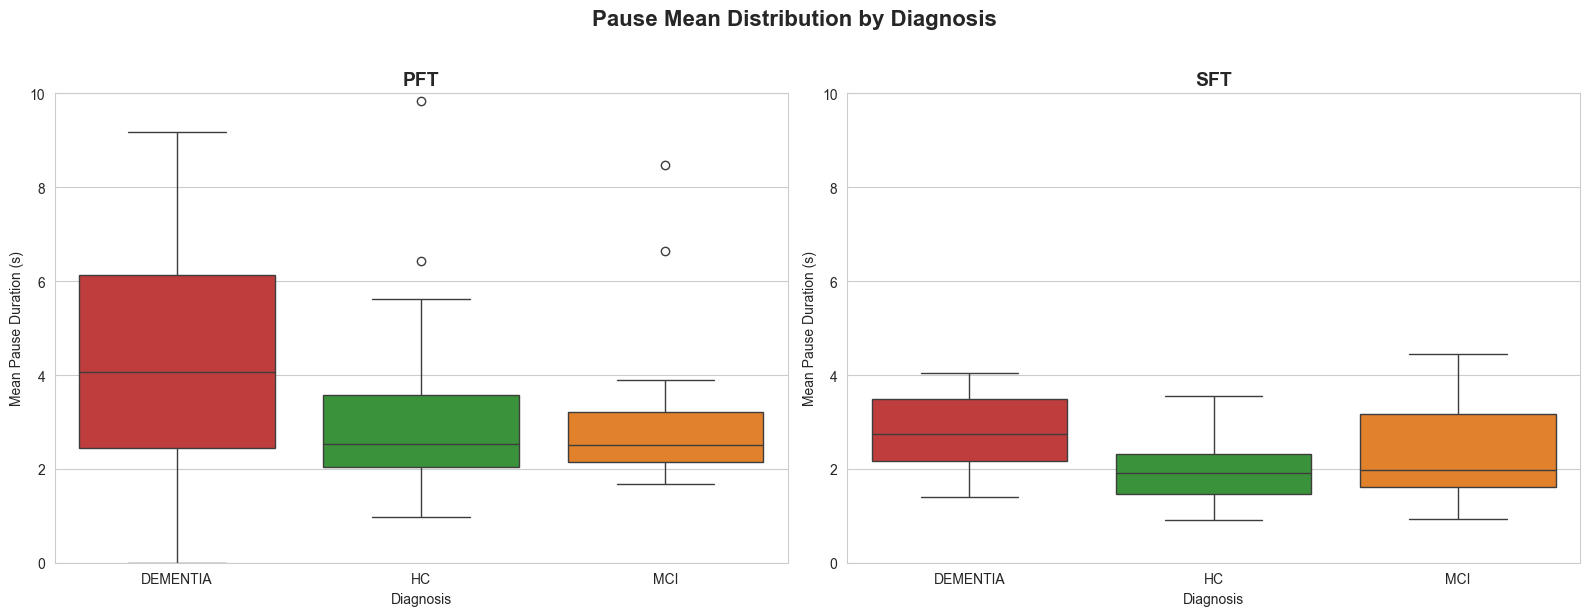


diagnosis Statistics:
           count      mean       std       25%       50%       75%
diagnosis                                                         
DEMENTIA    20.0  4.481135  2.654499  2.450600  4.073312  6.130733
HC          40.0  3.045205  1.639132  2.035556  2.523877  3.567045
MCI         30.0  4.206985  7.207549  2.151962  2.518115  3.222327

diagnosis Statistics:
           count      mean       std       25%       50%       75%
diagnosis                                                         
DEMENTIA    20.0  2.823146  0.839801  2.167873  2.752678  3.493559
HC          40.0  1.941722  0.693097  1.468108  1.906262  2.325128
MCI         30.0  2.308267  1.034430  1.616069  1.983833  3.160348


In [251]:
import re
from plotting import plot_3class_comparison, print_descriptive_stats

# Convert diagnosis to categorical with desired order
pause_with_diag['diagnosis'] = pd.Categorical(
    pause_with_diag['diagnosis'],
    categories=['DEMENTIA', 'HC', 'MCI'],
    ordered=True
)

# Extract task (PFT/SFT) from transcript path
pause_with_diag['task'] = pause_with_diag['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_filtered = pause_with_diag[pause_with_diag['task'].isin(['PFT', 'SFT'])].copy()

# Prepare data
pft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
sft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']

# Plot comparison
plot_3class_comparison(pft_data, sft_data)

# Print descriptive statistics
print_descriptive_stats(pft_data, 'diagnosis')
print_descriptive_stats(sft_data, 'diagnosis')


## Statistical Tests: 3-Class Comparison

Two-tailed independent samples t-tests to compare means between diagnosis groups.


TWO-TAILED T-TESTS: PFT

DEMENTIA vs HC:
  t-statistic: 2.5848
  p-value: 0.0123
  Significant (p < 0.05): Yes *

DEMENTIA vs MCI:
  t-statistic: 0.1625
  p-value: 0.8716
  Significant (p < 0.05): No 

MCI vs HC:
  t-statistic: 0.9882
  p-value: 0.3266
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

DEMENTIA vs HC:
  t-statistic: 4.3239
  p-value: 0.0001
  Significant (p < 0.05): Yes *

DEMENTIA vs MCI:
  t-statistic: 1.8538
  p-value: 0.0699
  Significant (p < 0.05): No 

MCI vs HC:
  t-statistic: 1.7740
  p-value: 0.0805
  Significant (p < 0.05): No 


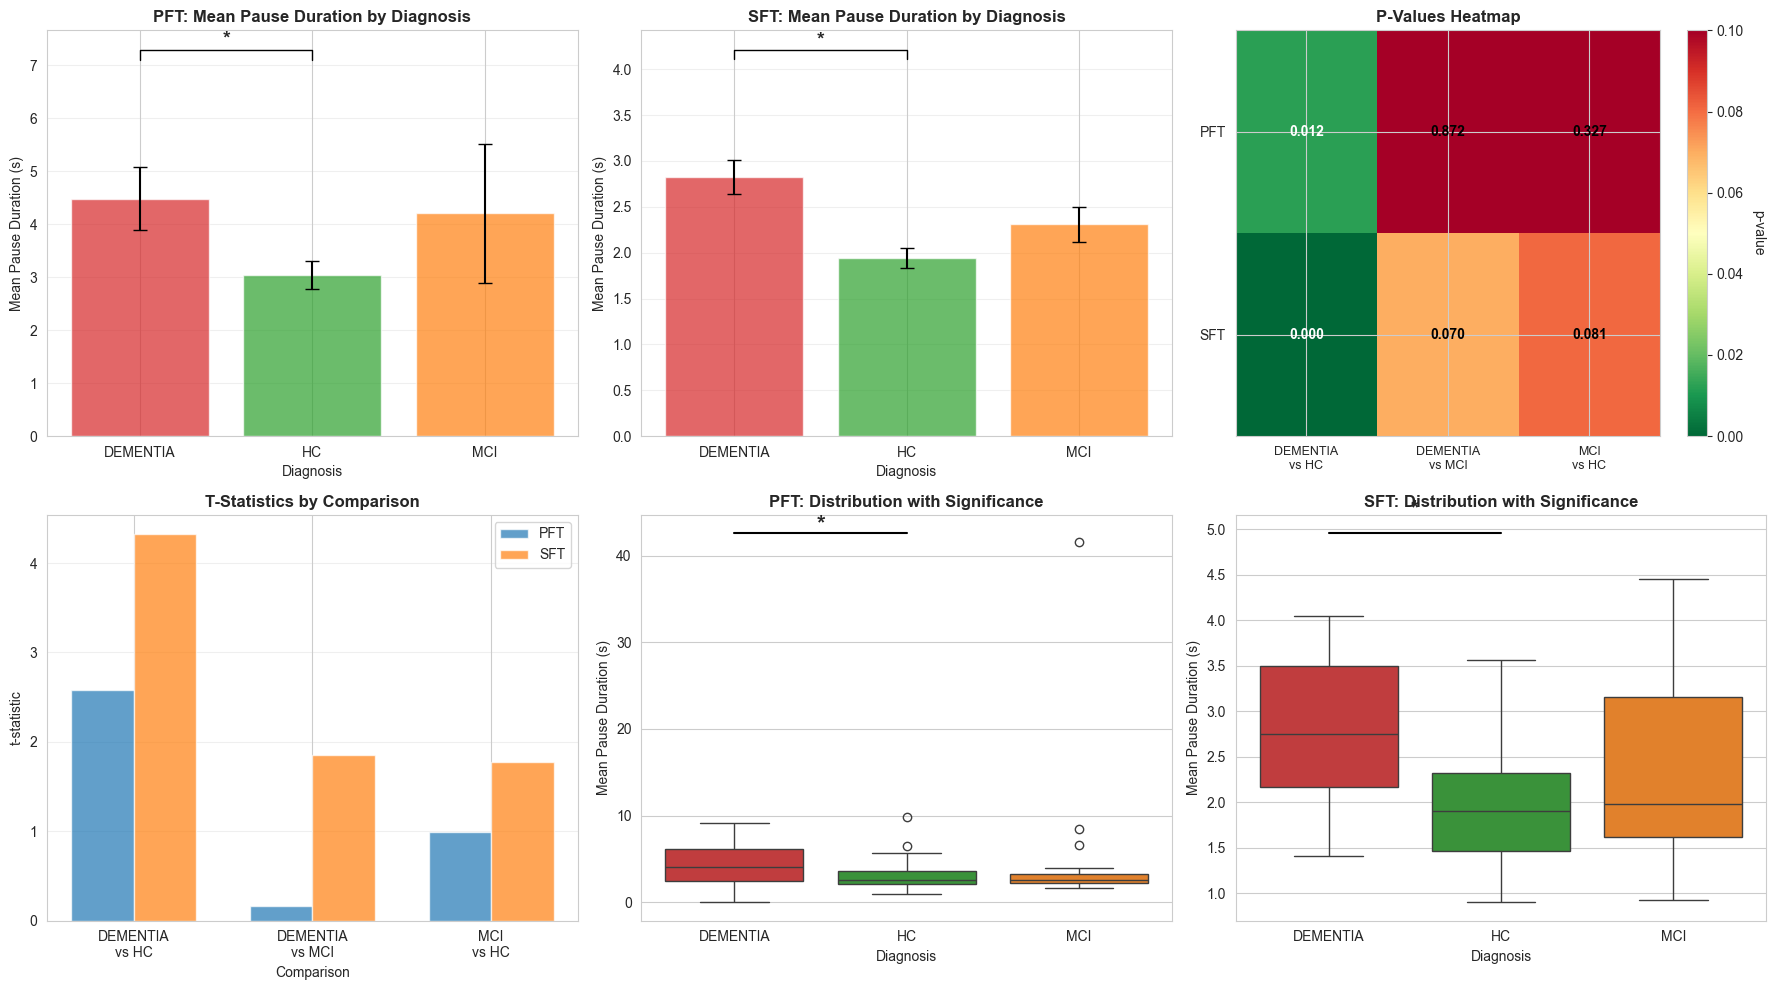


SUMMARY: Significant differences (p < 0.05) are marked with *


In [252]:
from statistical_tests import perform_3class_ttests, print_ttest_results, plot_3class_statistics

# Perform t-tests
test_results = perform_3class_ttests(pft_data, sft_data)

# Print results
print_ttest_results(test_results)

# Create visualizations
plot_3class_statistics(pft_data, sft_data, test_results)


## Healthy vs Non-Healthy by Task (PFT and SFT)

Compare Healthy vs Non-Healthy groups separately for PFT and SFT tasks.


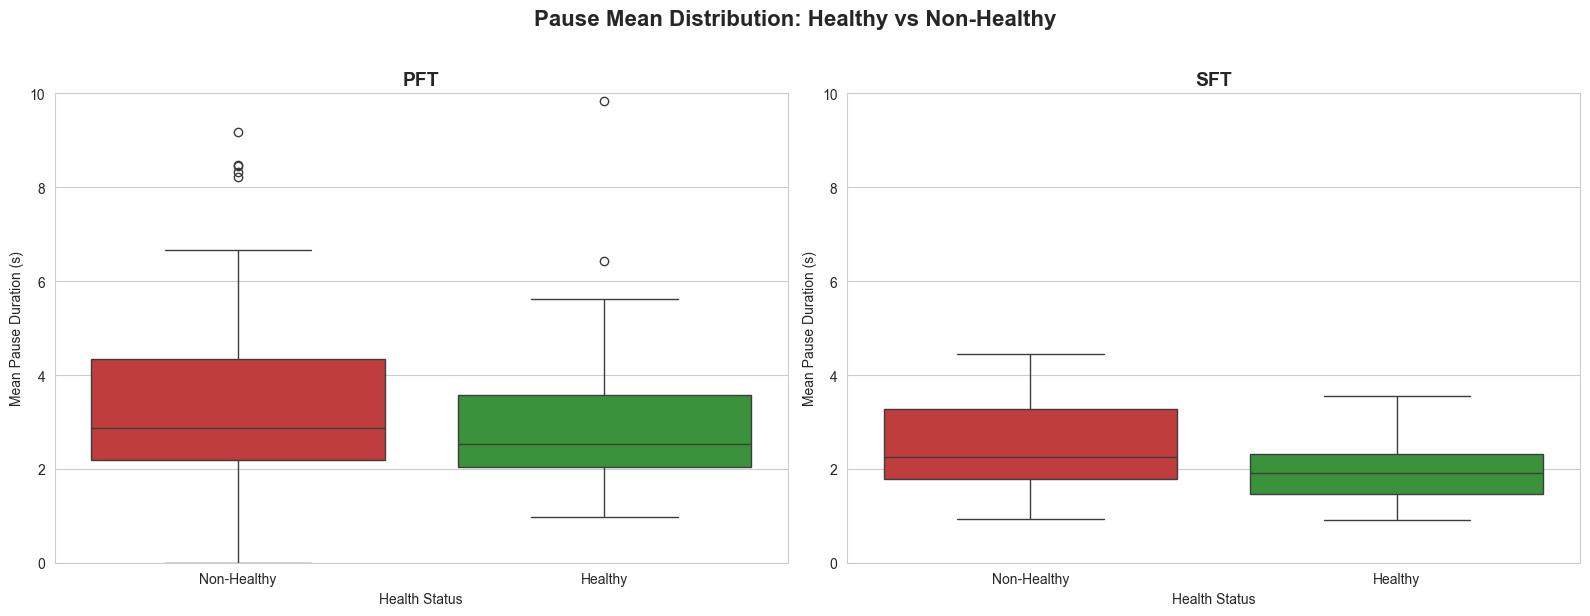


health_status Statistics:
               count      mean       std       25%       50%       75%
health_status                                                         
Non-Healthy     50.0  4.316645  5.787561  2.197804  2.872020  4.349339
Healthy         40.0  3.045205  1.639132  2.035556  2.523877  3.567045

health_status Statistics:
               count      mean       std       25%       50%       75%
health_status                                                         
Non-Healthy     50.0  2.514219  0.985741  1.774787  2.259599  3.279955
Healthy         40.0  1.941722  0.693097  1.468108  1.906262  2.325128


In [253]:
import re
from plotting import plot_binary_comparison, print_descriptive_stats

# Extract task (PFT/SFT) from transcript path (if not already done)
if 'task' not in pause_with_diag.columns:
    pause_with_diag['task'] = pause_with_diag['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_filtered = pause_with_diag[pause_with_diag['task'].isin(['PFT', 'SFT'])].copy()

# Create health_status if not already created
if 'health_status' not in pause_with_diag_filtered.columns:
    pause_with_diag_filtered['health_status'] = pause_with_diag_filtered['diagnosis'].apply(
        lambda x: 'Non-Healthy' if x in ['DEMENTIA', 'MCI'] else 'Healthy'
    )
    pause_with_diag_filtered['health_status'] = pd.Categorical(
        pause_with_diag_filtered['health_status'],
        categories=['Non-Healthy', 'Healthy'],
        ordered=True
    )

# Prepare data
pft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
sft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']

# Plot comparison
plot_binary_comparison(pft_data, sft_data)

# Print descriptive statistics
print_descriptive_stats(pft_data, 'health_status')
print_descriptive_stats(sft_data, 'health_status')


## Statistical Tests: Binary Comparison (Healthy vs Non-Healthy)

Two-tailed independent samples t-tests to compare means between Healthy and Non-Healthy groups.


TWO-TAILED T-TESTS: PFT

Healthy vs Non-Healthy:
  t-statistic: -1.3455
  p-value: 0.1819
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

Healthy vs Non-Healthy:
  t-statistic: -3.1081
  p-value: 0.0025
  Significant (p < 0.05): Yes *


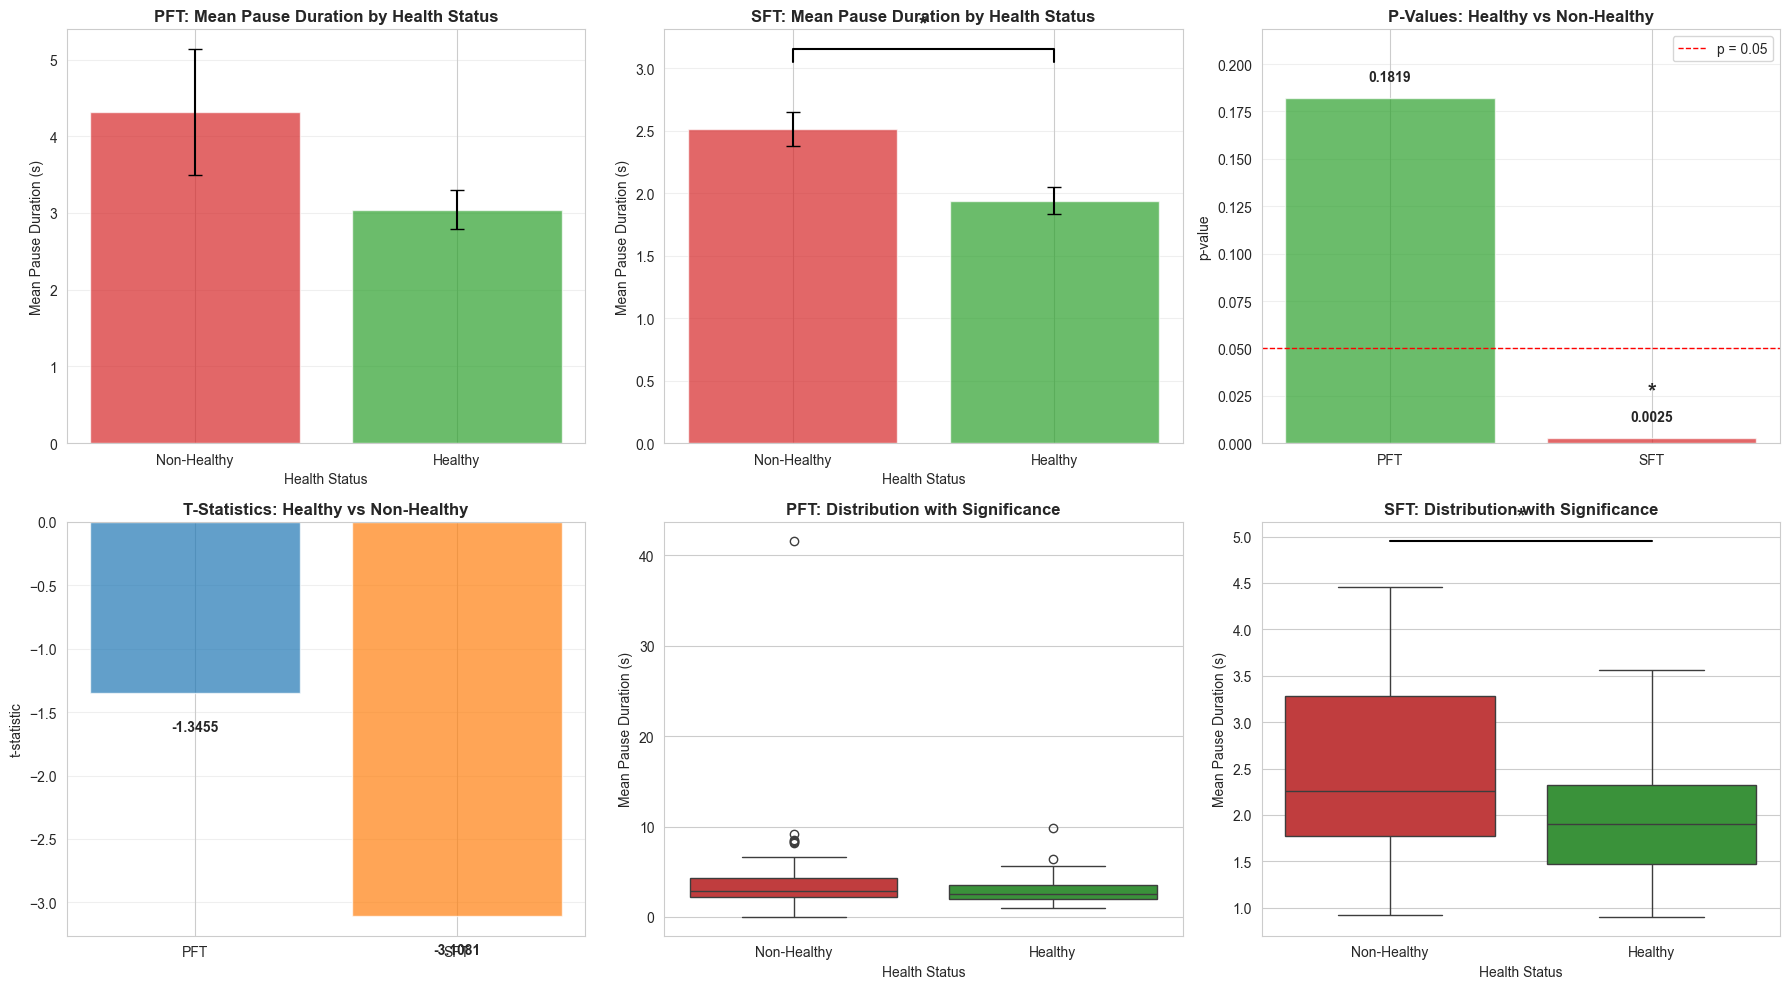


SUMMARY: Significant differences (p < 0.05) are marked with *


In [254]:
from statistical_tests import perform_binary_ttests, print_ttest_results, plot_binary_statistics

# Perform t-tests
test_results = perform_binary_ttests(pft_data, sft_data)

# Print results
print_ttest_results(test_results)

# Create visualizations
plot_binary_statistics(pft_data, sft_data, test_results)


## Binary Classifier: Dementia vs Healthy

Build a binary classifier using SFT pause metrics to distinguish Dementia (1) from Healthy (0). We'll use 5-fold cross-validation and visualize the results with a confusion matrix.


In [255]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report

from binary_classifier import build_feature_dataset, get_classifier

# Set style for plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 8)


In [256]:
# Build feature dataset using SFT pause metrics only
features_df = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False  # Use SFT only
)

print(f"Loaded {len(features_df)} recordings")
print(f"  - Dementia: {sum(features_df['label'] == 1)}")
print(f"  - Healthy (HC): {sum(features_df['label'] == 0)}")

# Prepare features and labels
feature_cols = [col for col in features_df.columns if col.startswith('sft_')]
X = features_df[feature_cols].fillna(0)
y = features_df['label']

print(f"\nUsing {len(feature_cols)} SFT pause features:")
for col in feature_cols:
    print(f"  - {col}")


Loaded 60 recordings
  - Dementia: 20
  - Healthy (HC): 40

Using 10 SFT pause features:
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3


In [257]:
# Perform 5-fold cross-validation and collect predictions for confusion matrix
k_folds = 5
cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
classifier = get_classifier('logistic')

# Store all predictions and true labels across folds
all_y_true = []
all_y_pred = []
fold_accuracies = []

print(f"Running {k_folds}-fold cross-validation...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # Train and predict
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)
    
    # Store predictions
    all_y_true.extend(y_test.values)
    all_y_pred.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    fold_accuracies.append(fold_acc)
    
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}")


Running 5-fold cross-validation...

Fold 1: Accuracy = 0.7500
Fold 2: Accuracy = 0.9167
Fold 3: Accuracy = 0.8333
Fold 4: Accuracy = 0.6667
Fold 5: Accuracy = 0.5833

Mean accuracy across 5 folds: 0.7500 ± 0.1179


In [258]:
# Generate confusion matrix
cm = confusion_matrix(all_y_true, all_y_pred)

# Print classification report
print("Classification Report (aggregated across all folds):")
print("=" * 60)
print(classification_report(all_y_true, all_y_pred, 
                          target_names=['Healthy (HC)', 'Dementia']))
print("=" * 60)


Classification Report (aggregated across all folds):
              precision    recall  f1-score   support

Healthy (HC)       0.79      0.85      0.82        40
    Dementia       0.65      0.55      0.59        20

    accuracy                           0.75        60
   macro avg       0.72      0.70      0.71        60
weighted avg       0.74      0.75      0.74        60



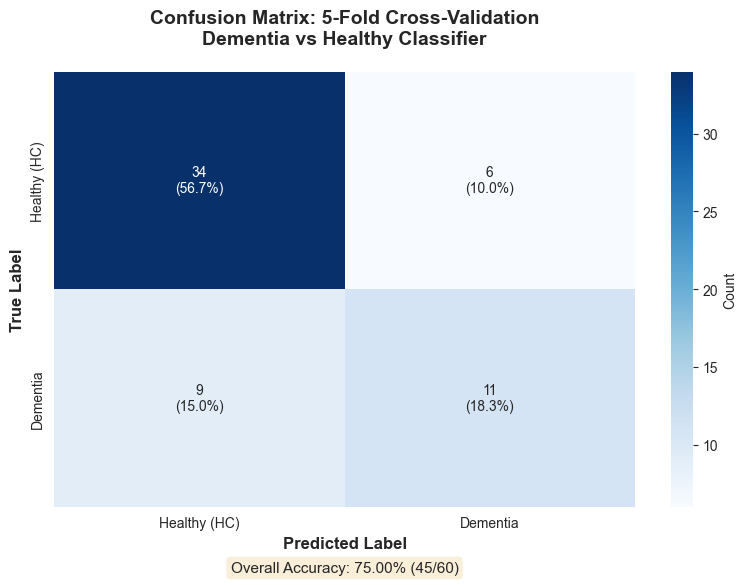

In [259]:
# Plot confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

# Calculate percentages of total sample
total_samples = cm.sum()
cm_percent_total = cm.astype('float') / total_samples * 100

# Create annotation labels with both count and percentage of total
annot_labels = []
for i in range(len(cm)):
    row = []
    for j in range(len(cm)):
        count = cm[i, j]
        percent = cm_percent_total[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

# Create heatmap with custom annotations
sns.heatmap(cm, annot=annot_labels, fmt='', cmap='Blues', 
            xticklabels=['Healthy (HC)', 'Dementia'],
            yticklabels=['Healthy (HC)', 'Dementia'],
            cbar_kws={'label': 'Count'},
            ax=ax)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix: 5-Fold Cross-Validation\nDementia vs Healthy Classifier', 
             fontsize=14, fontweight='bold', pad=20)

# Add accuracy text
total = cm.sum()
correct = np.trace(cm)
accuracy = correct / total
ax.text(0.5, -0.15, f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()


## Binary Classifier with Demographics: Age and Gender Features

Compare the binary classifier performance when including participant age and gender as additional features. This experiment tests whether demographic information improves the accuracy of distinguishing Dementia from Healthy controls.


In [260]:
# Build feature dataset with demographics (age and gender)
features_df_demo = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False,  # Use SFT only
    include_demographics=True  # Include age and gender
)

print(f"Loaded {len(features_df_demo)} recordings")
print(f"  - Dementia: {sum(features_df_demo['label'] == 1)}")
print(f"  - Healthy (HC): {sum(features_df_demo['label'] == 0)}")

# Prepare features and labels (including demographics)
feature_cols_demo = [col for col in features_df_demo.columns 
                    if col.startswith('sft_') or col == 'age' or col == 'gender_encoded']
X_demo = features_df_demo[feature_cols_demo].fillna(0)
y_demo = features_df_demo['label']

# Handle missing age values with median
if 'age' in X_demo.columns:
    age_median = X_demo['age'].median()
    if pd.notna(age_median):
        X_demo['age'] = X_demo['age'].fillna(age_median)
    else:
        X_demo['age'] = X_demo['age'].fillna(0)

print(f"\nUsing {len(feature_cols_demo)} features (including demographics):")
for col in feature_cols_demo:
    print(f"  - {col}")


Loaded 60 recordings
  - Dementia: 20
  - Healthy (HC): 40

Using 12 features (including demographics):
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3
  - age
  - gender_encoded


In [261]:
# Perform 5-fold cross-validation with demographics and collect predictions
k_folds = 5
cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
classifier_demo = get_classifier('logistic')

# Store all predictions and true labels across folds
all_y_true_demo = []
all_y_pred_demo = []
fold_accuracies_demo = []

print(f"Running {k_folds}-fold cross-validation with demographics...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X_demo, y_demo), 1):
    X_train, X_test = X_demo.iloc[train_idx], X_demo.iloc[test_idx]
    y_train, y_test = y_demo.iloc[train_idx], y_demo.iloc[test_idx]
    
    # Train and predict
    classifier_demo.fit(X_train, y_train)
    y_pred = classifier_demo.predict(X_test)
    
    # Store predictions
    all_y_true_demo.extend(y_test.values)
    all_y_pred_demo.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    fold_accuracies_demo.append(fold_acc)
    
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean(fold_accuracies_demo):.4f} ± {np.std(fold_accuracies_demo):.4f}")

# Compare with baseline (without demographics)
print(f"\nComparison:")
print(f"  Baseline (without demographics): {np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}")
print(f"  With demographics:              {np.mean(fold_accuracies_demo):.4f} ± {np.std(fold_accuracies_demo):.4f}")
improvement = np.mean(fold_accuracies_demo) - np.mean(fold_accuracies)
print(f"  Improvement:                    {improvement:+.4f} ({improvement*100:+.2f}%)")


Running 5-fold cross-validation with demographics...

Fold 1: Accuracy = 0.9167
Fold 2: Accuracy = 0.8333
Fold 3: Accuracy = 0.8333
Fold 4: Accuracy = 0.7500
Fold 5: Accuracy = 0.5000

Mean accuracy across 5 folds: 0.7667 ± 0.1434

Comparison:
  Baseline (without demographics): 0.7500 ± 0.1179
  With demographics:              0.7667 ± 0.1434
  Improvement:                    +0.0167 (+1.67%)


## Multiclass Classifier: Dementia vs MCI vs HC

Build a multiclass classifier using SFT pause metrics to distinguish all three classes: Healthy (HC), Mild Cognitive Impairment (MCI), and Dementia. This is an exploratory model to see how well we can distinguish all three groups.


In [262]:
# Generate confusion matrix for model with demographics
cm_demo = confusion_matrix(all_y_true_demo, all_y_pred_demo)

# Print classification report
print("Classification Report (with demographics, aggregated across all folds):")
print("=" * 60)
print(classification_report(all_y_true_demo, all_y_pred_demo, 
                          target_names=['Healthy (HC)', 'Dementia']))
print("=" * 60)


Classification Report (with demographics, aggregated across all folds):
              precision    recall  f1-score   support

Healthy (HC)       0.80      0.88      0.83        40
    Dementia       0.69      0.55      0.61        20

    accuracy                           0.77        60
   macro avg       0.74      0.71      0.72        60
weighted avg       0.76      0.77      0.76        60



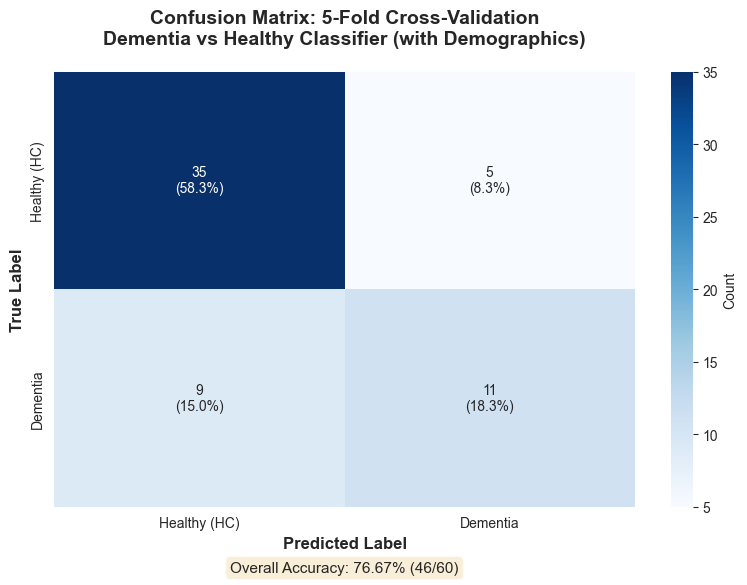

In [263]:
# Plot confusion matrix for model with demographics
fig, ax = plt.subplots(figsize=(8, 6))

# Calculate percentages of total sample
total_samples_demo = cm_demo.sum()
cm_percent_total_demo = cm_demo.astype('float') / total_samples_demo * 100

# Create annotation labels with both count and percentage of total
annot_labels_demo = []
for i in range(len(cm_demo)):
    row = []
    for j in range(len(cm_demo)):
        count = cm_demo[i, j]
        percent = cm_percent_total_demo[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels_demo.append(row)

# Create heatmap with custom annotations
sns.heatmap(cm_demo, annot=annot_labels_demo, fmt='', cmap='Blues', 
            xticklabels=['Healthy (HC)', 'Dementia'],
            yticklabels=['Healthy (HC)', 'Dementia'],
            cbar_kws={'label': 'Count'},
            ax=ax)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix: 5-Fold Cross-Validation\nDementia vs Healthy Classifier (with Demographics)', 
             fontsize=14, fontweight='bold', pad=20)

# Add accuracy text
total_demo = cm_demo.sum()
correct_demo = np.trace(cm_demo)
accuracy_demo = correct_demo / total_demo
ax.text(0.5, -0.15, f'Overall Accuracy: {accuracy_demo*100:.2f}% ({correct_demo}/{total_demo})',
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()


In [264]:
from multiclass_classifier import build_feature_dataset, get_classifier, evaluate_with_cv, print_cv_results, plot_confusion_matrix

# Build feature dataset for multiclass classification (includes MCI)
features_df_multiclass = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False  # Use SFT only
)

print(f"Loaded {len(features_df_multiclass)} recordings")
print("\nClass distribution:")
for label_val, count in features_df_multiclass['label'].value_counts().sort_index().items():
    diagnosis_name = features_df_multiclass[features_df_multiclass['label'] == label_val]['diagnosis'].iloc[0]
    print(f"  {diagnosis_name}: {count}")

# Prepare features and labels
feature_cols = [col for col in features_df_multiclass.columns if col.startswith('sft_')]
X_multiclass = features_df_multiclass[feature_cols].fillna(0)
y_multiclass = features_df_multiclass['label']

print(f"\nUsing {len(feature_cols)} SFT pause features:")
for col in feature_cols:
    print(f"  - {col}")


Loaded 90 recordings

Class distribution:
  HC: 40
  MCI: 30
  DEMENTIA: 20

Using 10 SFT pause features:
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3


In [265]:
# Perform 5-fold cross-validation for multiclass classification
k_folds = 5
classifier_multiclass = get_classifier('random_forest')  # Random Forest works well for multiclass

print(f"Performing {k_folds}-fold cross-validation for multiclass classification...")
cv_results_multiclass = evaluate_with_cv(X_multiclass, y_multiclass, classifier_multiclass, k_folds=k_folds)

# Display CV results as a pandas DataFrame
cv_results_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Mean': [
        cv_results_multiclass['accuracy_mean'],
        cv_results_multiclass['precision_mean'],
        cv_results_multiclass['recall_mean'],
        cv_results_multiclass['f1_mean']
    ],
    'Std': [
        cv_results_multiclass['accuracy_std'],
        cv_results_multiclass['precision_std'],
        cv_results_multiclass['recall_std'],
        cv_results_multiclass['f1_std']
    ]
})
cv_results_df['Mean ± Std'] = cv_results_df.apply(
    lambda row: f"{row['Mean']:.4f} ± {row['Std']:.4f}", axis=1
)
cv_results_df = cv_results_df[['Metric', 'Mean ± Std']]

print("\n" + "=" * 80)
print("K-FOLD CROSS-VALIDATION RESULTS (Multiclass: HC vs MCI vs Dementia)")
print("=" * 80)
display(cv_results_df)
print("=" * 80 + "\n")


Performing 5-fold cross-validation for multiclass classification...

K-FOLD CROSS-VALIDATION RESULTS (Multiclass: HC vs MCI vs Dementia)


,Metric,Mean ± Std
0,Accuracy,0.5222 ± 0.1247
1,Precision (Macro),0.5969 ± 0.1224
2,Recall (Macro),0.5056 ± 0.1371
3,F1-Score (Macro),0.5065 ± 0.1279


In [266]:
# Collect predictions across all folds for confusion matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
all_y_true_multiclass = []
all_y_pred_multiclass = []

print(f"Running {k_folds}-fold cross-validation to collect predictions...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X_multiclass, y_multiclass), 1):
    X_train, X_test = X_multiclass.iloc[train_idx], X_multiclass.iloc[test_idx]
    y_train, y_test = y_multiclass.iloc[train_idx], y_multiclass.iloc[test_idx]
    
    # Train and predict
    classifier_multiclass.fit(X_train, y_train)
    y_pred = classifier_multiclass.predict(X_test)
    
    # Store predictions
    all_y_true_multiclass.extend(y_test.values)
    all_y_pred_multiclass.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean([(np.array(all_y_pred_multiclass)[i::k_folds] == np.array(all_y_true_multiclass)[i::k_folds]).mean() for i in range(k_folds)]):.4f}")


Running 5-fold cross-validation to collect predictions...

Fold 1: Accuracy = 0.7222
Fold 2: Accuracy = 0.5000
Fold 3: Accuracy = 0.3333
Fold 4: Accuracy = 0.5000
Fold 5: Accuracy = 0.5556

Mean accuracy across 5 folds: 0.5222


In [267]:
# Create detailed classification report as pandas DataFrame

# Calculate per-class metrics
precision, recall, f1, support = precision_recall_fscore_support(
    all_y_true_multiclass,
    all_y_pred_multiclass,
    labels=[0, 1, 2],
    zero_division=0
)

# Create DataFrame
class_names = ['HC', 'MCI', 'Dementia']
classification_results_df = pd.DataFrame({
    'Class': class_names,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support
})

# Format for display
classification_results_df['Precision'] = classification_results_df['Precision'].apply(lambda x: f'{x:.4f}')
classification_results_df['Recall'] = classification_results_df['Recall'].apply(lambda x: f'{x:.4f}')
classification_results_df['F1-Score'] = classification_results_df['F1-Score'].apply(lambda x: f'{x:.4f}')

print("\n" + "=" * 80)
print("DETAILED CLASSIFICATION REPORT (Per-Class Metrics)")
print("=" * 80)
display(classification_results_df)

# Calculate overall accuracy
overall_accuracy = accuracy_score(all_y_true_multiclass, all_y_pred_multiclass)
print(f"\nOverall Accuracy: {overall_accuracy:.4f} ({overall_accuracy*100:.2f}%)")
print(f"Total Samples: {len(all_y_true_multiclass)}")
print("=" * 80 + "\n")



DETAILED CLASSIFICATION REPORT (Per-Class Metrics)


,Class,Precision,Recall,F1-Score,Support
0,HC,0.5217,0.6000,0.5581,40
1,MCI,0.5000,0.4667,0.4828,30
2,Dementia,0.5625,0.4500,0.5000,20



Overall Accuracy: 0.5222 (52.22%)
Total Samples: 90



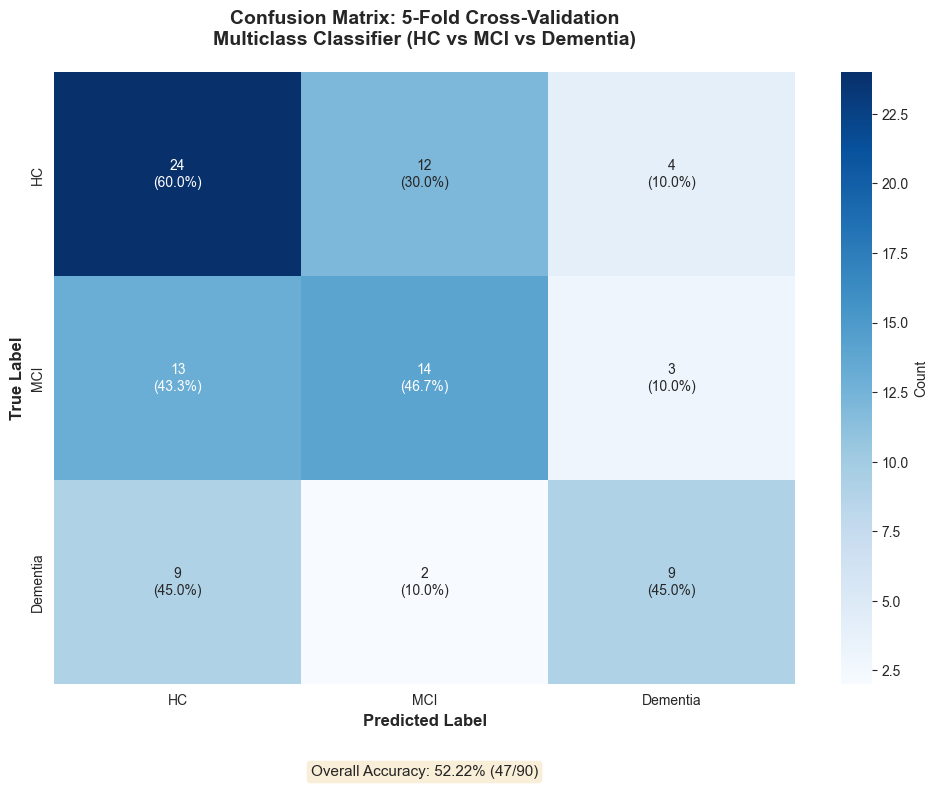

In [268]:
# Plot confusion matrix for multiclass classification
cm_multiclass = confusion_matrix(all_y_true_multiclass, all_y_pred_multiclass)

fig, ax = plt.subplots(figsize=(10, 8))

# Calculate percentages of each row (true class)
# This ensures each row sums to exactly 100%
row_sums = cm_multiclass.sum(axis=1)
# Avoid division by zero (shouldn't happen, but safety check)
row_sums = np.where(row_sums == 0, 1, row_sums)

# Calculate percentages and normalize to ensure each row sums to exactly 100%
cm_percent = np.zeros_like(cm_multiclass, dtype=float)
for i in range(len(cm_multiclass)):
    if row_sums[i] > 0:
        # Calculate percentages for this row
        cm_percent[i, :] = cm_multiclass[i, :].astype('float') / row_sums[i] * 100
        # Ensure it sums to exactly 100% by normalizing
        row_total = cm_percent[i, :].sum()
        if row_total > 0:
            cm_percent[i, :] = cm_percent[i, :] / row_total * 100

# Create annotation labels with both count and percentage
annot_labels = []
class_names = ['HC', 'MCI', 'Dementia']
for i in range(len(cm_multiclass)):
    row = []
    for j in range(len(cm_multiclass)):
        count = cm_multiclass[i, j]
        percent = cm_percent[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

# Create heatmap
sns.heatmap(
    cm_multiclass, 
    annot=annot_labels, 
    fmt='', 
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Count'},
    ax=ax
)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title(
    'Confusion Matrix: 5-Fold Cross-Validation\nMulticlass Classifier (HC vs MCI vs Dementia)',
    fontsize=14,
    fontweight='bold',
    pad=20
)

# Add accuracy text
total = cm_multiclass.sum()
correct = np.trace(cm_multiclass)
accuracy = correct / total
ax.text(
    0.5, -0.15,
    f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
    transform=ax.transAxes,
    ha='center',
    fontsize=11,
    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5)
)

plt.tight_layout()
plt.show()


In [269]:
# Display confusion matrix as pandas DataFrame
cm_df = pd.DataFrame(
    cm_multiclass,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

# Add row totals
cm_df['Total'] = cm_df.sum(axis=1)

# Calculate percentages for each row
cm_percent_df = pd.DataFrame(
    cm_percent,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Counts)")
print("=" * 80)
display(cm_df)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Percentages - each row sums to 100%)")
print("=" * 80)
# Format percentages
cm_percent_df_formatted = cm_percent_df.applymap(lambda x: f'{x:.1f}%')
display(cm_percent_df_formatted)
print("=" * 80 + "\n")



CONFUSION MATRIX (Counts)


,Pred: HC,Pred: MCI,Pred: Dementia,Total
True: HC,24,12,4,40
True: MCI,13,14,3,30
True: Dementia,9,2,9,20



CONFUSION MATRIX (Percentages - each row sums to 100%)


/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_37496/3657399134.py:27: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  cm_percent_df_formatted = cm_percent_df.applymap(lambda x: f'{x:.1f}%')


,Pred: HC,Pred: MCI,Pred: Dementia
True: HC,60.0%,30.0%,10.0%
True: MCI,43.3%,46.7%,10.0%
True: Dementia,45.0%,10.0%,45.0%
